In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                              roc_curve, roc_auc_score, precision_recall_curve, RocCurveDisplay)
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
UP_BLUE, UP_RED, UP_GOLD = "#003366", "#BA0C2F", "#C69214"

# EDA


In [5]:
df = pd.read_csv("./16P.csv", encoding='cp1252')



In [6]:
print(df.shape)
df.head()

(59999, 62)


,Response Id,You regularly make new friends.,You spend a lot of your free time exploring various random topics that pique your interest,Seeing other people cry can easily make you feel like you want to cry too,You often make a backup plan for a backup plan.,"You usually stay calm, even under a lot of pressure","At social events, you rarely try to introduce yourself to new people and mostly talk to the ones you already know",You prefer to completely finish one project before starting another.,You are very sentimental.,You like to use organizing tools like schedules and lists.,...,You believe that pondering abstract philosophical questions is a waste of time.,"You feel more drawn to places with busy, bustling atmospheres than quiet, intimate places.",You know at first glance how someone is feeling.,You often feel overwhelmed.,You complete things methodically without skipping over any steps.,You are very intrigued by things labeled as controversial.,You would pass along a good opportunity if you thought someone else needed it more.,You struggle with deadlines.,You feel confident that things will work out for you.,Personality
0,0,0,0,0,0,0,1,1,0,0,...,0,0,0,-1,0,0,0,0,0,ENFP
1,1,0,0,-2,-3,-1,2,-2,0,3,...,0,-2,0,2,0,-1,-1,-1,3,ISFP
2,2,0,0,2,0,-1,2,0,0,1,...,0,2,0,2,-1,0,1,2,1,INFJ
3,3,0,-1,3,-1,0,0,-2,0,-2,...,0,0,-1,-1,0,1,0,-2,-1,ISTP
4,4,0,0,-1,0,2,-1,-2,0,1,...,0,1,0,2,0,1,-1,2,-1,ENFJ


In [7]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 59999 entries, 0 to 59998
Data columns (total 62 columns):
 #   Column                                                                                                                Non-Null Count  Dtype
---  ------                                                                                                                --------------  -----
 0   Response Id                                                                                                           59999 non-null  int64
 1   You regularly make new friends.                                                                                       59999 non-null  int64
 2   You spend a lot of your free time exploring various random topics that pique your interest                            59999 non-null  int64
 3   Seeing other people cry can easily make you feel like you want to cry too                                             59999 non-null  int64
 4   You often make a backup pla

In [8]:
#Quitar duplicados y NaN
df = df.drop_duplicates()
df = df.dropna()
print(df.shape)

(59999, 62)


In [9]:
print(df["Personality"].value_counts())

Personality
ESFP    3769
INFJ    3761
ENFP    3760
ENTP    3760
ESTJ    3759
ISTJ    3756
ISTP    3755
ESTP    3749
ISFP    3746
ESFJ    3746
ENFJ    3743
INTJ    3743
INTP    3742
ISFJ    3739
ENTJ    3737
INFP    3734
Name: count, dtype: int64


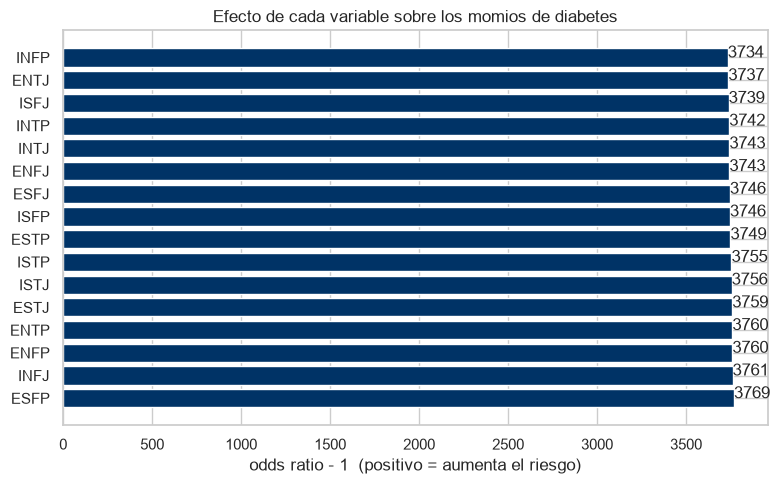

In [10]:
conteo = df["Personality"].value_counts()  

plt.figure(figsize=(8, 5))
plt.barh(conteo.index.astype(str), conteo.values, color=UP_BLUE)

for x,y in enumerate(conteo.values):
    plt.text(y,x,f"{y}")


plt.xlabel("odds ratio - 1  (positivo = aumenta el riesgo)")
plt.title("Efecto de cada variable sobre los momios de diabetes")
plt.tight_layout()
plt.show()

In [12]:
#Desvaición estándar de cada variable con la objetivo
df.groupby("Personality").std()

,Response Id,You regularly make new friends.,You spend a lot of your free time exploring various random topics that pique your interest,Seeing other people cry can easily make you feel like you want to cry too,You often make a backup plan for a backup plan.,"You usually stay calm, even under a lot of pressure","At social events, you rarely try to introduce yourself to new people and mostly talk to the ones you already know",You prefer to completely finish one project before starting another.,You are very sentimental.,You like to use organizing tools like schedules and lists.,...,You would love a job that requires you to work alone most of the time.,You believe that pondering abstract philosophical questions is a waste of time.,"You feel more drawn to places with busy, bustling atmospheres than quiet, intimate places.",You know at first glance how someone is feeling.,You often feel overwhelmed.,You complete things methodically without skipping over any steps.,You are very intrigued by things labeled as controversial.,You would pass along a good opportunity if you thought someone else needed it more.,You struggle with deadlines.,You feel confident that things will work out for you.
Personality,,,,,,,,,,,,,,,,,,,,,
ENFJ,17232.456072,0.371995,0.380209,1.523541,1.210218,1.570666,1.229426,1.185494,0.372327,1.503959,...,0.360378,0.374538,1.139058,0.369175,1.098831,0.373131,0.372407,1.509869,1.500438,1.549036
ENFP,17356.750224,0.369414,0.352441,1.233254,1.174339,1.528641,1.511052,1.537818,0.371879,1.195003,...,0.371930,0.364571,1.532577,0.368997,1.226670,0.375070,0.369912,1.091449,1.224151,1.590397
ENTJ,17504.867057,0.366885,0.359883,1.218996,1.150583,1.090765,1.205332,1.573695,0.352396,1.554760,...,0.368265,0.369105,1.561746,0.362874,1.514520,0.367944,0.373433,1.511303,1.426282,1.228613
ENTP,17327.338133,0.362516,0.364701,1.206962,1.195537,1.089242,1.206752,1.122598,0.372889,1.536629,...,0.372642,0.367220,1.248479,0.371903,1.480200,0.363400,0.361406,1.177141,1.205546,1.159072
ESFJ,17337.869631,0.370397,0.366272,1.550216,1.521433,1.126570,1.551472,1.271184,0.366832,1.573731,...,0.368644,0.367919,1.105021,0.358751,1.227517,0.359853,0.364646,1.228332,1.552416,1.505197
ESFP,17263.501542,0.353914,0.377445,1.177707,1.541706,1.146448,1.507526,1.538604,0.367762,1.557081,...,0.363088,0.362814,1.508880,0.369294,1.202426,0.380299,0.357879,1.609479,1.494254,1.226301
ESTJ,17562.776245,0.353987,0.362189,1.142787,1.292965,1.513007,1.156291,1.190732,0.374833,1.199012,...,0.355143,0.381168,1.553882,0.369111,1.225590,0.353269,0.358876,1.573834,1.148547,1.601580
ESTP,17297.543264,0.366698,0.362302,1.524623,1.210473,1.294619,1.491781,1.510267,0.362679,1.528168,...,0.370324,0.359618,1.184661,0.361134,1.174658,0.366617,0.372832,1.573762,1.566635,1.551079
INFJ,17332.045118,0.367011,0.371423,1.229358,1.253207,1.132786,1.224541,1.519271,0.376137,1.241903,...,0.366819,0.359784,1.538641,0.378266,1.180870,0.357662,0.375081,1.130245,1.558172,1.537408


In [14]:
numerical_features = df.drop(columns="Personality")
plt.figure(figsize=(13, 13))
sns.heatmap(df[numerical_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlacion entre variables numericas")
plt.show()

TypeError: Boolean array expected for the condition, not int64

<Figure size 1300x1300 with 0 Axes>

# MATRIZ DE DISEÑO

In [15]:

X = df.drop(columns=["Personality"])
y = df["Personality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.30,random_state=42,stratify=y
)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# LDA o QDA


In [16]:
LDA_model = LinearDiscriminantAnalysis()
LDA_model.fit(X_train_s, y_train)
y_pred_lda = LDA_model.predict(X_test_s)

In [17]:
print(accuracy_score(y_test, y_pred_lda))

0.9056111111111111


# KNN

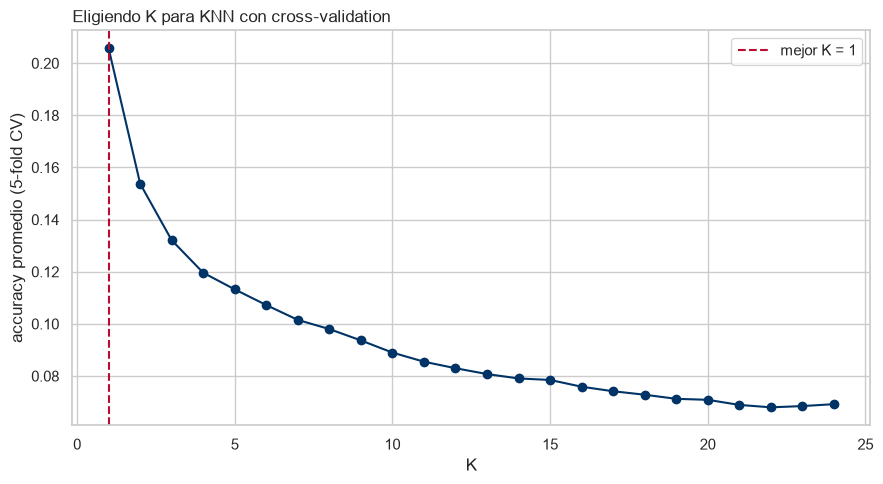

In [18]:
k_grid = range(1, 25)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in k_grid]
best_k = list(k_grid)[int(np.argmax(cv_scores))]

plt.figure(figsize=(9, 5))
plt.plot(list(k_grid), cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_k, color=UP_RED, ls="--", label=f"mejor K = {best_k}")
plt.xlabel("K")
plt.ylabel("accuracy promedio (5-fold CV)")
plt.title("Eligiendo K para KNN con cross-validation", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
KNN_model = KNeighborsClassifier(n_neighbors=best_k)
KNN_model.fit(X_train_s, y_train)
y_pred_knn = KNN_model.predict(X_test_s)

In [20]:
print(accuracy_score(y_test, y_pred_knn))

0.9555555555555556


In [21]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

        ENFJ       0.95      0.97      0.96      1123
        ENFP       0.97      0.97      0.97      1128
        ENTJ       0.96      0.95      0.96      1121
        ENTP       0.96      0.97      0.96      1128
        ESFJ       0.95      0.95      0.95      1124
        ESFP       0.96      0.97      0.96      1131
        ESTJ       0.97      0.96      0.97      1128
        ESTP       0.95      0.98      0.96      1125
        INFJ       0.96      0.94      0.95      1128
        INFP       0.96      0.95      0.96      1120
        INTJ       0.95      0.95      0.95      1123
        INTP       0.94      0.94      0.94      1122
        ISFJ       0.96      0.95      0.96      1122
        ISFP       0.96      0.93      0.95      1124
        ISTJ       0.94      0.94      0.94      1127
        ISTP       0.95      0.96      0.96      1126

    accuracy                           0.96     18000
   macro avg       0.96   

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred_knn, display_labels="hool", cmap="Blues", values_format="d", ax=ax, colorbar=False)
        ax.set_title(f"{nombre}\nacc = {resultados[nombre]:.3f}", fontsize=11)

plt.tight_layout()
plt.show()

# Árbol

In [ ]:
arbol_completo = DecisionTreeClassifier(random_state=42)
path = arbol_completo.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]

cv_scores = []
for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(tree, X_train, y_train, cv=3, scoring="accuracy")
    cv_scores.append(scores.mean())

best_alpha = ccp_alphas[int(np.argmax(cv_scores))]
print(f"Mejor alpha por CV: {best_alpha:.4f}")

model_dt_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
model_dt_pruned.fit(X_train, y_train)

y_pred_dt = model_dt_pruned.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_dt, zero_division=0))

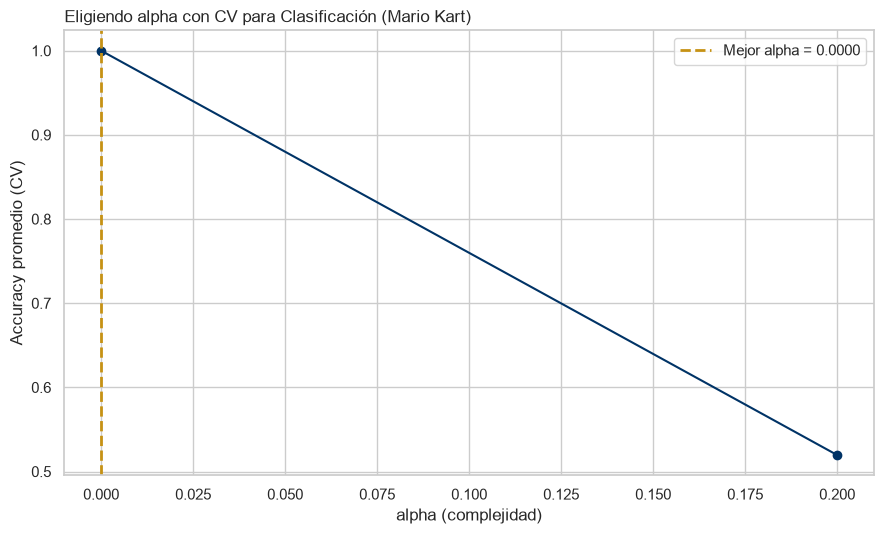

In [15]:
plt.figure(figsize=(9, 5.5))
plt.plot(ccp_alphas, cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_alpha, color=UP_GOLD, ls="--", lw=2, label=f"Mejor alpha = {best_alpha:.4f}")
plt.xlabel("alpha (complejidad)")
plt.ylabel("Accuracy promedio (CV)")
plt.title("Eligiendo alpha con CV para Clasificación (Mario Kart)", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
arbol_podado = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha).fit(X_train, y_train)
arbol_sin_podar = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

comparacion = pd.DataFrame({
    "modelo": ["Sin podar", "Podado (CV)"],
    "n_hojas": [arbol_sin_podar.get_n_leaves(), arbol_podado.get_n_leaves()],
    "accuracy_test": [
        accuracy_score(y_test, arbol_sin_podar.predict(X_test)),
        accuracy_score(y_test, arbol_podado.predict(X_test)),
    ],
}).round(3)
comparacion

,modelo,n_hojas,accuracy_test
0,Sin podar,5,1.0
1,Podado (CV),5,1.0


# Ensamble

# Observaciones

Pocos datos para muchas clases, no se puede entrenar bien el modelo y por eso nos arroja un accuracy muy bajo. Tampoco se pueden podar los árboles, ya que al intentar simplificar el arbol, solo logra que el accuracy del test baje.